## Лабораторна робота №1: Базові алгоритми класифікації у Scikit-learn
### ФБ-61мп Невмержицька Дар'я

### **Мета роботи:** Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.
### Хід роботи: 

*Частина 1:* Завантаження та первинний аналіз даних: завантажити датасет; вивести назви колонок та розмір датасета; визначити ознаки (features) та цільову змінну (target); перевірити типи даних та розподіл об'єктів за класами.

Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


1.1. Завантаження датасету

In [ ]:
df = pd.read_csv("cybersecurity_attacks.csv")
df.head()


,Timestamp,Source IP Address,Destination IP Address,Source Port,Destination Port,Protocol,Packet Length,Packet Type,Traffic Type,Payload Data,...,Action Taken,Severity Level,User Information,Device Information,Network Segment,Geo-location Data,Proxy Information,Firewall Logs,IDS/IPS Alerts,Log Source
0,2023-05-30 06:33:58,103.216.15.12,84.9.164.252,31225,17616,ICMP,503,Data,HTTP,Qui natus odio asperiores nam. Optio nobis ius...,...,Logged,Low,Reyansh Dugal,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment A,"Jamshedpur, Sikkim",150.9.97.135,Log Data,NaN,Server
1,2020-08-26 07:08:30,78.199.217.198,66.191.137.154,17245,48166,ICMP,1174,Data,HTTP,Aperiam quos modi officiis veritatis rem. Omni...,...,Blocked,Low,Sumer Rana,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment B,"Bilaspur, Nagaland",NaN,Log Data,NaN,Firewall
2,2022-11-13 08:23:25,63.79.210.48,198.219.82.17,16811,53600,UDP,306,Control,HTTP,Perferendis sapiente vitae soluta. Hic delectu...,...,Ignored,Low,Himmat Karpe,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,Segment C,"Bokaro, Rajasthan",114.133.48.179,Log Data,Alert Data,Firewall
3,2023-07-02 10:38:46,163.42.196.10,101.228.192.255,20018,32534,UDP,385,Data,HTTP,Totam maxime beatae expedita explicabo porro l...,...,Blocked,Medium,Fateh Kibe,Mozilla/5.0 (Macintosh; PPC Mac OS X 10_11_5; ...,Segment B,"Jaunpur, Rajasthan",NaN,NaN,Alert Data,Firewall
4,2023-07-16 13:11:07,71.166.185.76,189.243.174.238,6131,26646,TCP,1462,Data,DNS,Odit nesciunt dolorem nisi iste iusto. Animi v...,...,Blocked,Low,Dhanush Chad,Mozilla/5.0 (compatible; MSIE 5.0; Windows NT ...,Segment C,"Anantapur, Tripura",149.6.110.119,NaN,Alert Data,Firewall


1.2. Виведення назв колонок та розміру датасету

In [274]:

print("Назви колонок датасету:")
print(df.columns.tolist())

print("\nРозмір датасету:")
print(f"Кількість рядків: {df.shape[0]}")
print(f"Кількість колонок: {df.shape[1]}")


Назви колонок датасету:
['Timestamp', 'Source IP Address', 'Destination IP Address', 'Source Port', 'Destination Port', 'Protocol', 'Packet Length', 'Packet Type', 'Traffic Type', 'Payload Data', 'Malware Indicators', 'Anomaly Scores', 'Alerts/Warnings', 'Attack Type', 'Attack Signature', 'Action Taken', 'Severity Level', 'User Information', 'Device Information', 'Network Segment', 'Geo-location Data', 'Proxy Information', 'Firewall Logs', 'IDS/IPS Alerts', 'Log Source']

Розмір датасету:
Кількість рядків: 40000
Кількість колонок: 25


1.3. Перегляд випадкових записів датасету

In [275]:
df.sample(5).T

,368,5842,28914,5930,32611
Timestamp,2021-03-28 22:40:08,2023-04-05 10:15:22,2020-07-03 11:50:45,2021-07-08 21:34:25,2022-07-31 20:05:54
Source IP Address,73.233.145.125,223.160.123.98,54.128.236.69,197.215.173.47,111.106.138.10
Destination IP Address,69.239.237.186,34.206.168.187,186.252.195.200,133.109.103.63,136.181.168.119
Source Port,37416,59549,48217,21921,17689
Destination Port,24621,5471,35860,61696,50169
Protocol,TCP,UDP,TCP,ICMP,ICMP
Packet Length,412,1235,410,369,1145
Packet Type,Control,Data,Data,Control,Control
Traffic Type,DNS,HTTP,DNS,HTTP,DNS
Payload Data,Impedit sint rerum. In repudiandae quae. Commo...,Vitae rem a tempora.\nBeatae veniam deleniti i...,Omnis cum molestiae veniam soluta. Repudiandae...,Eaque exercitationem adipisci rem. Nostrum a n...,Neque inventore ex repellat. Praesentium ipsa ...


1.4. Перевірка типів даних

In [276]:

print("Типи даних кожної колонки:")
print(df.dtypes)

print("\nЗагальна інформація про датасет:")
df.info()


Типи даних кожної колонки:
Timestamp                     str
Source IP Address             str
Destination IP Address        str
Source Port                 int64
Destination Port            int64
Protocol                      str
Packet Length               int64
Packet Type                   str
Traffic Type                  str
Payload Data                  str
Malware Indicators            str
Anomaly Scores            float64
Alerts/Warnings               str
Attack Type                   str
Attack Signature              str
Action Taken                  str
Severity Level                str
User Information              str
Device Information            str
Network Segment               str
Geo-location Data             str
Proxy Information             str
Firewall Logs                 str
IDS/IPS Alerts                str
Log Source                    str
dtype: object

Загальна інформація про датасет:
<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data colum

1.5. Визначення ознак (features) та цільової змінної (target)

Для класифікації використали характеристики мережевого трафіку. Цільовою змінною обрано IDS/IPS Alerts. У межах дослідження сформовано два класи: 1 — наявність значення «Alert Data», 0 — відсутність заповненого значення у відповідному полі. Таким чином, модель прогнозує наявність або відсутність запису про сповіщення IDS/IPS на основі характеристик мережевого трафіку. При цьому пропущене значення не обов'язково означає фактичну відсутність сповіщення.

In [277]:

# Формування набору ознак
features = [
    "Source Port",
    "Destination Port",
    "Protocol",
    "Packet Length",
    "Packet Type",
    "Traffic Type",
    "Malware Indicators",
    "Anomaly Scores",
    "Severity Level",
    "Network Segment"
]

# Цільова змінна
target = "IDS/IPS Alerts"


X = df[features].copy()
y = df[target].eq("Alert Data").astype(int)

print("Кількість ознак:", len(features))
print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

print("\nРозподіл цільової змінної:")
print(y.value_counts())


Кількість ознак: 10
Розмір X: (40000, 10)
Розмір y: (40000,)

Розподіл цільової змінної:
IDS/IPS Alerts
0    20050
1    19950
Name: count, dtype: int64


1.6. Перевірка унікальних значень цільової змінної

In [ ]:

print("Унікальні значення цільової змінної:")
print(df[target].unique())

print("\nКількість унікальних значень:")
print(df[target].nunique(dropna=False))

# Перевірка можливості використання Attack Type
print("Розподіл Attack Type:")
print(df["Attack Type"].value_counts(dropna=False))

print("\nКількість пропусків:")
print(df["Attack Type"].isna().sum())

print("\nКількість класів:")
print(df["Attack Type"].nunique(dropna=True))


Унікальні значення цільової змінної:
<StringArray>
[nan, 'Alert Data']
Length: 2, dtype: str

Кількість унікальних значень:
2
Розподіл Attack Type:
Attack Type
DDoS         13428
Malware      13307
Intrusion    13265
Name: count, dtype: int64

Кількість пропусків:
0

Кількість класів:
3


1.7. Аналіз розподілу об'єктів за класами

In [279]:

print("Кількість об'єктів кожного класу:")
print(y.value_counts().sort_index())

print("\nРозподіл класів у відсотках:")
print(
    (y.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nПозначення класів:")
print("0 - IDS/IPS сповіщення відсутнє")
print("1 - IDS/IPS сповіщення зафіксовано")


Кількість об'єктів кожного класу:
IDS/IPS Alerts
0    20050
1    19950
Name: count, dtype: int64

Розподіл класів у відсотках:
IDS/IPS Alerts
0    50.12
1    49.88
Name: proportion, dtype: float64

Позначення класів:
0 - IDS/IPS сповіщення відсутнє
1 - IDS/IPS сповіщення зафіксовано


1.8. Візуалізація розподілу класів

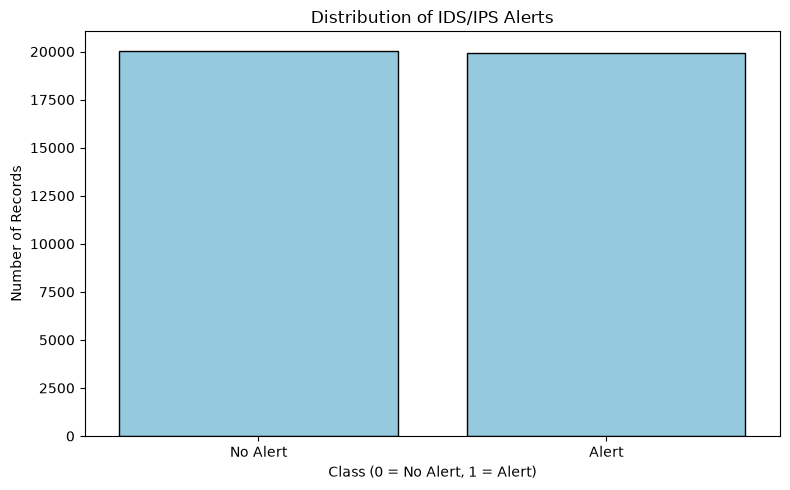

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of IDS/IPS Alerts")
plt.xlabel("Class (0 = No Alert, 1 = Alert)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Alert", "Alert"])
plt.tight_layout()
plt.show()


*Частина 2:* Попередня обробка даних: перевірити наявність пропущених значень; за необхідності заповнити або видалити пропуски; якщо датасет містить категоріальні ознаки, виконати їх кодування; коротко пояснити прийняті рішення щодо попередньої обробки даних.

2.1. Перевірка наявності пропущених значень

In [281]:

print("Кількість пропущених значень у кожній колонці:")
print(df.isnull().sum())

print("\nЗагальна кількість пропущених значень:")
print(df.isnull().sum().sum())


Кількість пропущених значень у кожній колонці:
Timestamp                     0
Source IP Address             0
Destination IP Address        0
Source Port                   0
Destination Port              0
Protocol                      0
Packet Length                 0
Packet Type                   0
Traffic Type                  0
Payload Data                  0
Malware Indicators        20000
Anomaly Scores                0
Alerts/Warnings           20067
Attack Type                   0
Attack Signature              0
Action Taken                  0
Severity Level                0
User Information              0
Device Information            0
Network Segment               0
Geo-location Data             0
Proxy Information         19851
Firewall Logs             19961
IDS/IPS Alerts            20050
Log Source                    0
dtype: int64

Загальна кількість пропущених значень:
99929


2.2. Визначення відсотка пропущених значень

In [282]:

missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing (%)": missing_percent.round(2)
})

print("Аналіз пропущених значень:")
print(missing_table.sort_values(
    by="Missing (%)",
    ascending=False
))


Аналіз пропущених значень:
                        Missing Values  Missing (%)
Alerts/Warnings                  20067        50.17
IDS/IPS Alerts                   20050        50.12
Malware Indicators               20000        50.00
Firewall Logs                    19961        49.90
Proxy Information                19851        49.63
Source IP Address                    0         0.00
Destination IP Address               0         0.00
Source Port                          0         0.00
Timestamp                            0         0.00
Traffic Type                         0         0.00
Packet Type                          0         0.00
Packet Length                        0         0.00
Protocol                             0         0.00
Destination Port                     0         0.00
Attack Type                          0         0.00
Payload Data                         0         0.00
Anomaly Scores                       0         0.00
Severity Level                       

2.3. Заповнення пропущених значень

Для категоріальної ознаки Malware Indicators пропущені значення замінимо на Unknown. Аналогічний підхід застосуємо до інших категоріальних ознак, що дозволить зберегти інформацію про відсутні значення. Пропуски в числових ознаках заповнимо медіаною, оскільки вона є менш чутливою до викидів.

In [283]:

# Створення копії вибраних ознак
X = df[features].copy()

# Заповнення пропусків у Malware Indicators
X["Malware Indicators"] = X["Malware Indicators"].fillna(
    "Unknown"
)

print(X["Malware Indicators"].value_counts(dropna=False))

# Визначення числових та категоріальних ознак
# Числові ознаки
numerical_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

# Категоріальні ознаки
categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Заповнення числових пропусків
for column in numerical_features:
    X[column] = X[column].fillna(X[column].median())

# Заповнення категоріальних пропусків
for column in categorical_features:
    X[column] = X[column].fillna("Unknown")

print("Пропущені значення після обробки:")
print(X.isnull().sum())


Malware Indicators
IoC Detected    20000
Unknown         20000
Name: count, dtype: int64


Пропущені значення після обробки:
Source Port           0
Destination Port      0
Protocol              0
Packet Length         0
Packet Type           0
Traffic Type          0
Malware Indicators    0
Anomaly Scores        0
Severity Level        0
Network Segment       0
dtype: int64


2.4. Визначення категоріальних та числових ознак

In [284]:

print("Числові ознаки:")
print(numerical_features)

print("\nКатегоріальні ознаки:")
print(categorical_features)

print("\nКількість числових ознак:", len(numerical_features))
print("Кількість категоріальних ознак:", len(categorical_features))


Числові ознаки:
['Source Port', 'Destination Port', 'Packet Length', 'Anomaly Scores']

Категоріальні ознаки:
['Protocol', 'Packet Type', 'Traffic Type', 'Malware Indicators', 'Severity Level', 'Network Segment']

Кількість числових ознак: 4
Кількість категоріальних ознак: 6


2.5. Аналіз унікальних значень категоріальних ознак

In [285]:

for column in categorical_features:
    unique_values = X[column].unique()

    print(f"\nКолонка: {column}")
    print(f"Кількість унікальних значень: {len(unique_values)}")
    print("Значення:", unique_values[:15])



Колонка: Protocol
Кількість унікальних значень: 3
Значення: <StringArray>
['ICMP', 'UDP', 'TCP']
Length: 3, dtype: str

Колонка: Packet Type
Кількість унікальних значень: 2
Значення: <StringArray>
['Data', 'Control']
Length: 2, dtype: str

Колонка: Traffic Type
Кількість унікальних значень: 3
Значення: <StringArray>
['HTTP', 'DNS', 'FTP']
Length: 3, dtype: str

Колонка: Malware Indicators
Кількість унікальних значень: 2
Значення: <StringArray>
['IoC Detected', 'Unknown']
Length: 2, dtype: str

Колонка: Severity Level
Кількість унікальних значень: 3
Значення: <StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Колонка: Network Segment
Кількість унікальних значень: 3
Значення: <StringArray>
['Segment A', 'Segment B', 'Segment C']
Length: 3, dtype: str


2.6. Кодування категоріальних ознак

Для перетворення категоріальних значень у числовий формат використаємо pd.get_dummies()

In [286]:

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    dtype=int
)

print("Розмір даних до кодування:", X.shape)
print("Розмір даних після кодування:", X_encoded.shape)

print("\nНазви колонок після кодування:")
print(X_encoded.columns.tolist())


Розмір даних до кодування: (40000, 10)
Розмір даних після кодування: (40000, 20)

Назви колонок після кодування:
['Source Port', 'Destination Port', 'Packet Length', 'Anomaly Scores', 'Protocol_ICMP', 'Protocol_TCP', 'Protocol_UDP', 'Packet Type_Control', 'Packet Type_Data', 'Traffic Type_DNS', 'Traffic Type_FTP', 'Traffic Type_HTTP', 'Malware Indicators_IoC Detected', 'Malware Indicators_Unknown', 'Severity Level_High', 'Severity Level_Low', 'Severity Level_Medium', 'Network Segment_Segment A', 'Network Segment_Segment B', 'Network Segment_Segment C']


2.7. Перегляд закодованих даних

In [287]:

print("Перші 5 записів після кодування:")
print(X_encoded.head())

print("\nВипадкові 5 записів:")
print(X_encoded.sample(5).T)


Перші 5 записів після кодування:
   Source Port  Destination Port  Packet Length  Anomaly Scores  \
0        31225             17616            503           28.67   
1        17245             48166           1174           51.50   
2        16811             53600            306           87.42   
3        20018             32534            385           15.79   
4         6131             26646           1462            0.52   

   Protocol_ICMP  Protocol_TCP  Protocol_UDP  Packet Type_Control  \
0              1             0             0                    0   
1              1             0             0                    0   
2              0             0             1                    1   
3              0             0             1                    0   
4              0             1             0                    0   

   Packet Type_Data  Traffic Type_DNS  Traffic Type_FTP  Traffic Type_HTTP  \
0                 1                 0                 0                

2.8. Перевірка результатів попередньої обробки

In [288]:

print("Загальна кількість пропусків:")
print(X_encoded.isnull().sum().sum())

print("\nТипи даних після кодування:")
print(X_encoded.dtypes.value_counts())

print("\nРозмір обробленого датасету:")
print(X_encoded.shape)

if X_encoded.isnull().sum().sum() == 0:
    print("\nПропущених значень немає.")
else:
    print("\nУ датасеті залишилися пропущені значення.")

if all(pd.api.types.is_numeric_dtype(dtype)
       for dtype in X_encoded.dtypes):
    print("Усі ознаки мають числовий формат.")
else:
    print("Не всі ознаки мають числовий формат.")


Загальна кількість пропусків:
0

Типи даних після кодування:
int64      19
float64     1
Name: count, dtype: int64

Розмір обробленого датасету:
(40000, 20)

Пропущених значень немає.
Усі ознаки мають числовий формат.


2.9. Пояснення прийнятих рішень щодо попередньої обробки даних

Для обробки пропущених значень було обрано метод заповнення, а не видалення записів, оскільки видалення рядків могло б призвести до втрати значної частини даних. Пропуски в категоріальних ознаках доцільно було замінити окремими значеннями, щоб зберегти інформацію про відсутні дані. Для числових ознак обрано заповнення медіаною, оскільки вона менш чутлива до викидів і незначно впливає на загальний розподіл значень.
Для кодування категоріальних ознак використано метод One-Hot Encoding, оскільки алгоритми машинного навчання потребують числового представлення даних. Цей метод дозволяє перетворити категорії на бінарні ознаки без створення штучного порядку між ними.
Такий підхід дозволив зберегти максимальну кількість записів, уникнути втрати потенційно корисної інформації та підготувати дані для подальшого навчання моделей класифікації.

*Частина 3:* Візуалізація та дослідження даних - провести базовий Exploratory Data Analysis (EDA): побудувати heatmap кореляцій числових ознак; побудувати гістограми розподілу ознак; побудувати boxplot-и ознак відносно цільової змінної; коротко прокоментувати отримані візуалізації.

3.1. Побудова теплової карти кореляцій (Heatmap)
Для визначення взаємозв'язків між числовими ознаками та цільовою змінною побудовано кореляційну матрицю.

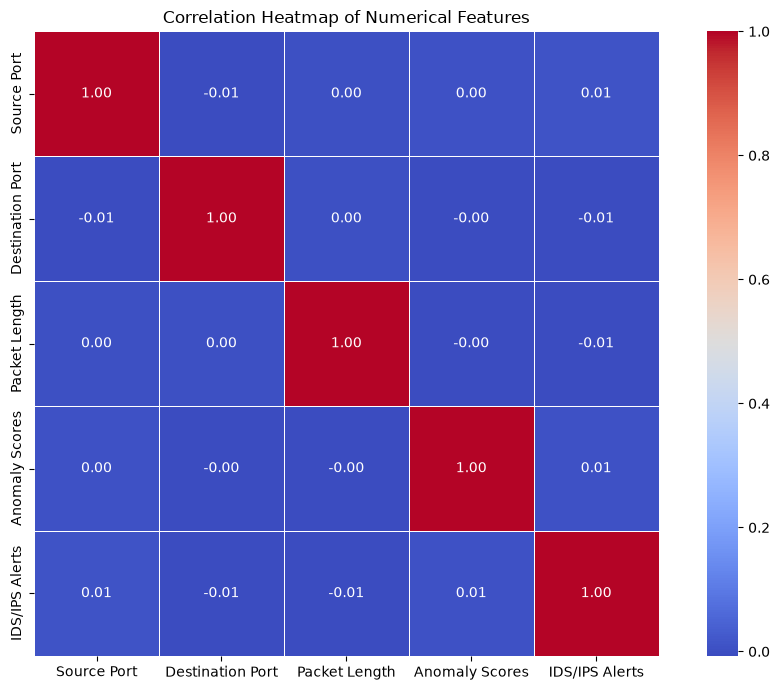

In [289]:

# Вибір числових ознак
numeric_data = X[numerical_features].copy()

# Додавання цільової змінної
numeric_data["IDS/IPS Alerts"] = y.values

# Обчислення кореляційної матриці
correlation_matrix = numeric_data.corr()

# Побудова heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


Кореляційний аналіз дозволив оцінити лінійні взаємозв'язки між числовими ознаками Source Port, Destination Port, Packet Length, Anomaly Scores та цільовою змінною IDS/IPS Alerts. Отримані результати свідчать про дуже слабкий лінійний зв'язок між досліджуваними числовими характеристиками та цільовою змінною. Це може ускладнювати класифікацію мережевого трафіку на основі вибраних ознак.

3.2. Аналіз кореляції ознак із цільовою змінною
Визначимо, які числові ознаки мають найсильніший лінійний зв'язок із IDS/IPS Alerts.

In [290]:

target_correlation = correlation_matrix[
    "IDS/IPS Alerts"
].drop("IDS/IPS Alerts")

print("Кореляція числових ознак із цільовою змінною:")
print(
    target_correlation.sort_values(
        key=abs,
        ascending=False
    )
)


Кореляція числових ознак із цільовою змінною:
Source Port         0.009650
Destination Port   -0.007217
Anomaly Scores      0.005534
Packet Length      -0.005180
Name: IDS/IPS Alerts, dtype: float64


3.3. Побудова гістограм розподілу числових ознак

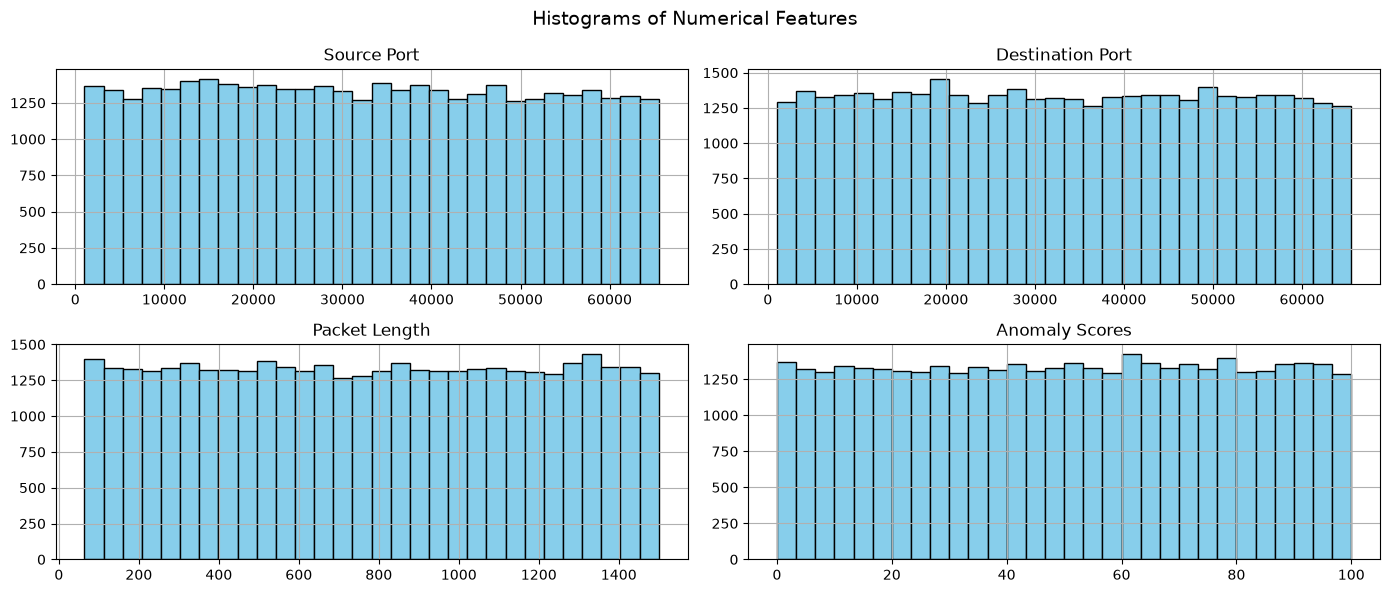

In [291]:

X[numerical_features].hist(
    bins=30,
    figsize=(14, 6),
    color="skyblue",
    edgecolor="black"
)

plt.suptitle(
    "Histograms of Numerical Features",
    fontsize=14
)

plt.tight_layout()
plt.show()


Гістограми показують, що значення Packet Length та Anomaly Scores розподілені приблизно рівномірно в межах своїх діапазонів. Значних скупчень значень або вираженої асиметрії не спостерігається. Це свідчить про відносно рівномірне представлення різних значень числових ознак у датасеті.

3.4. Побудова гістограм розподілу категоріальних ознак
Для аналізу категоріальних ознак використано countplot, який відображає кількість об'єктів кожної категорії.

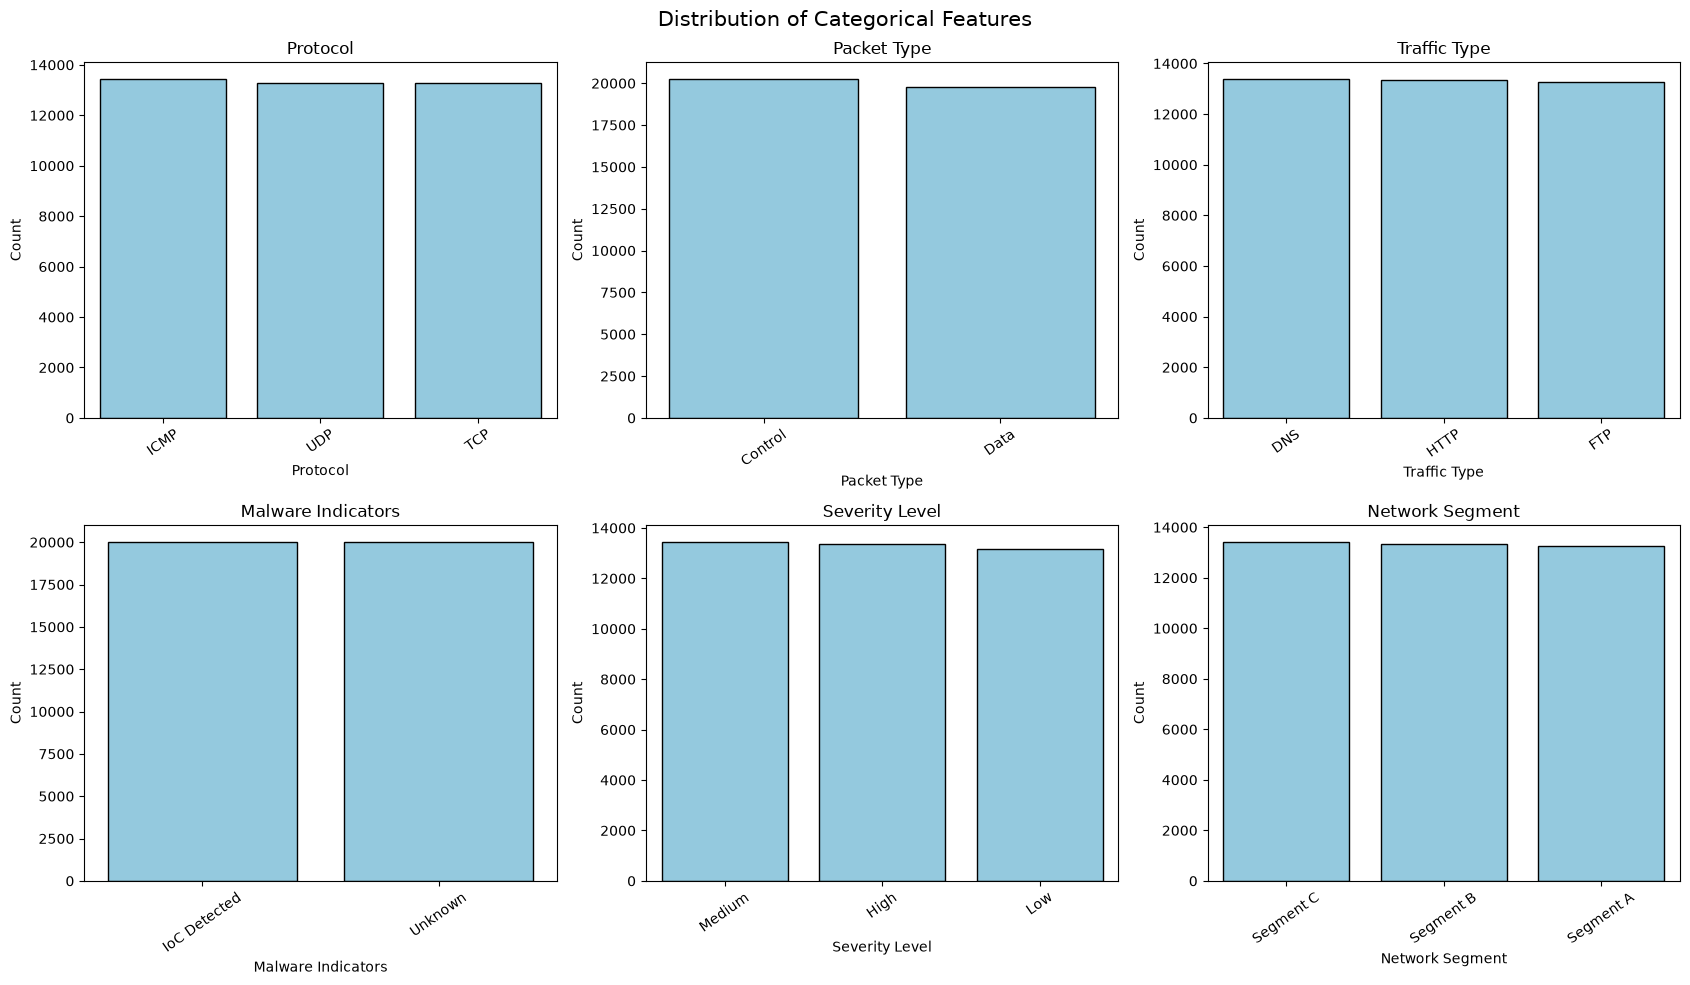

In [292]:

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, column in enumerate(categorical_features):

    sns.countplot(
        data=X,
        x=column,
        ax=axes[i],
        color="skyblue",
        edgecolor="black",
        order=X[column].value_counts().index
    )

    axes[i].set_title(column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=35)

# Видалення зайвих порожніх графіків
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribution of Categorical Features",
    fontsize=15
)

plt.tight_layout()
plt.show()


Аналіз категоріальних ознак показав, що значення Protocol, Packet Type, Traffic Type, Malware Indicators та Severity Level мають приблизно рівномірний розподіл. Жодна категорія суттєво не переважає над іншими, що свідчить про відсутність вираженого дисбалансу категорій у досліджуваних ознаках.

3.5. Побудова гістограм числових ознак відносно цільової змінної

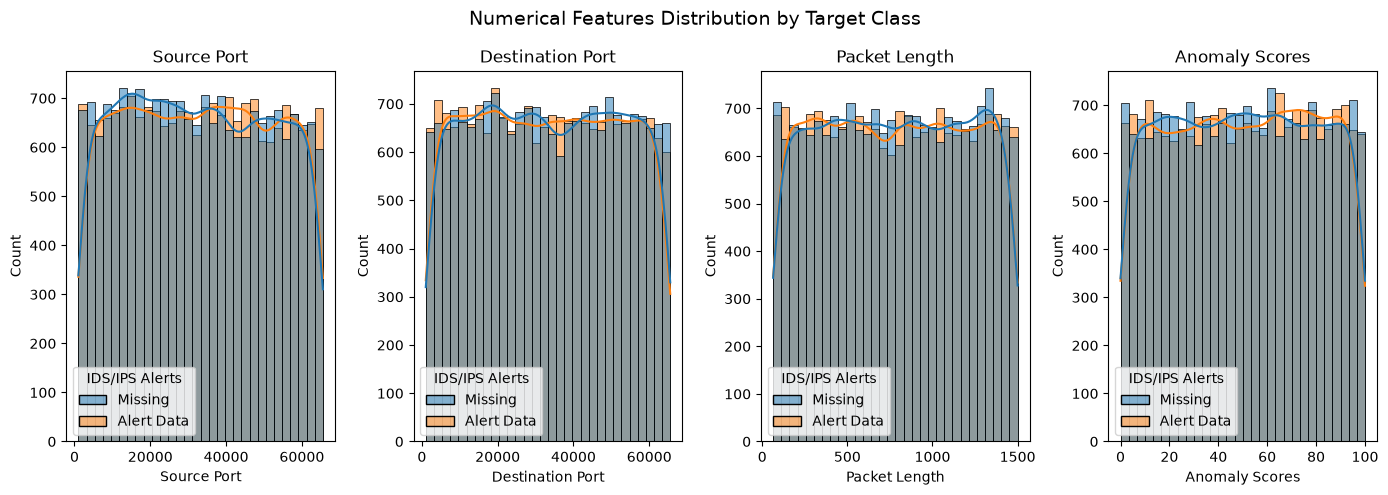

In [293]:

# Створення датафрейму для візуалізації
eda_data = X.copy()

eda_data["IDS/IPS Alerts"] = y.map({0: "Missing", 1: "Alert Data"}).values

# Побудова гістограм за класами
fig, axes = plt.subplots(
    1,
    len(numerical_features),
    figsize=(14, 5)
)

axes = np.atleast_1d(axes)

for i, column in enumerate(numerical_features):

    sns.histplot(
        data=eda_data,
        x=column,
        hue="IDS/IPS Alerts",
        bins=30,
        kde=True,
        alpha=0.5,
        ax=axes[i]
    )

    axes[i].set_title(column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Count")

plt.suptitle(
    "Numerical Features Distribution by Target Class",
    fontsize=14
)

plt.tight_layout()
plt.show()


Побудовані гістограми демонструють розподіли числових ознак Source Port, Destination Port, Packet Length та Anomaly Scores для класів Missing і Alert Data. Розподіли значною мірою перекриваються, що свідчить про відсутність виражених відмінностей між класами за досліджуваними числовими характеристиками. Отже, окремі числові ознаки мають обмежену здатність розрізняти записи із заповненим і пропущеним значенням IDS/IPS Alerts.

3.6. Побудова boxplot-графіків числових ознак відносно цільової змінної

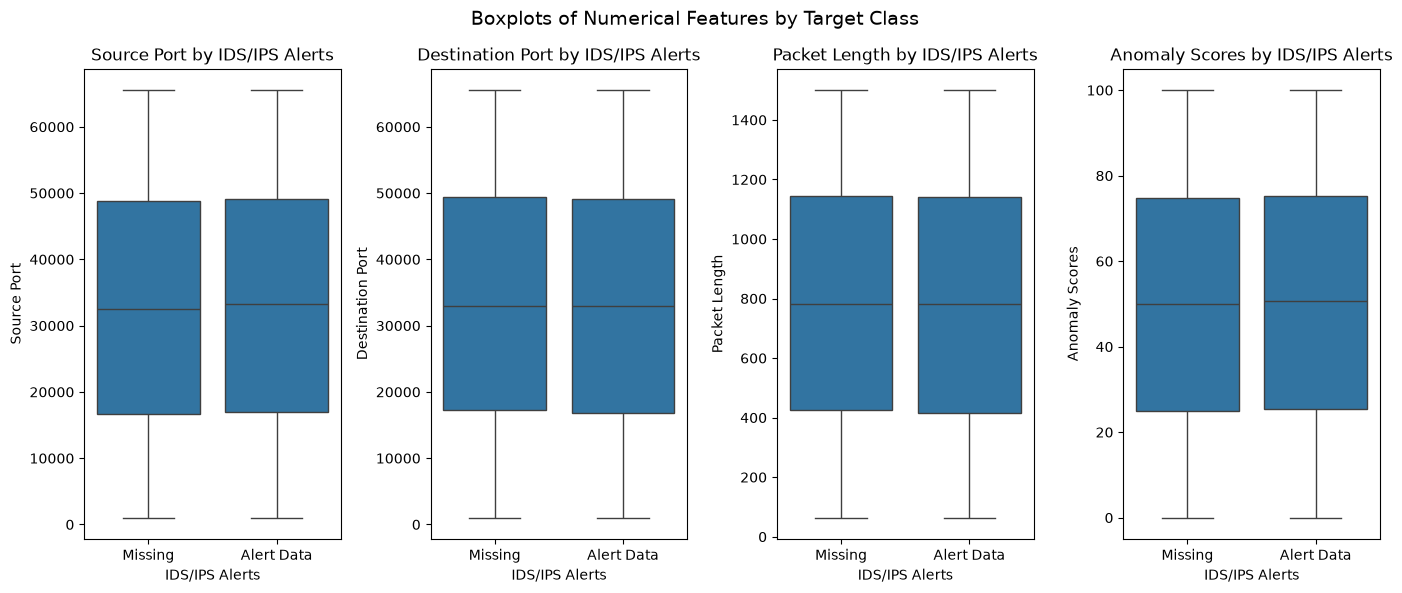

In [294]:

fig, axes = plt.subplots(
    1,
    len(numerical_features),
    figsize=(14, 6)
)

axes = np.atleast_1d(axes)

for i, column in enumerate(numerical_features):

    sns.boxplot(
        data=eda_data,
        x="IDS/IPS Alerts",
        y=column,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} by IDS/IPS Alerts")
    axes[i].set_xlabel("IDS/IPS Alerts")
    axes[i].set_ylabel(column)

plt.suptitle(
    "Boxplots of Numerical Features by Target Class",
    fontsize=14
)

plt.tight_layout()
plt.show()


Діаграми розмаху дозволили порівняти розподіли числових ознак Source Port, Destination Port, Packet Length та Anomaly Scores для класів Missing і Alert Data. Медіанні значення та міжквартильні діапазони для більшості досліджуваних ознак є близькими. Це свідчить про відсутність суттєвих відмінностей між класами за відповідними числовими характеристиками.

3.7. Побудова boxplot для Anomaly Scores за рівнем небезпеки

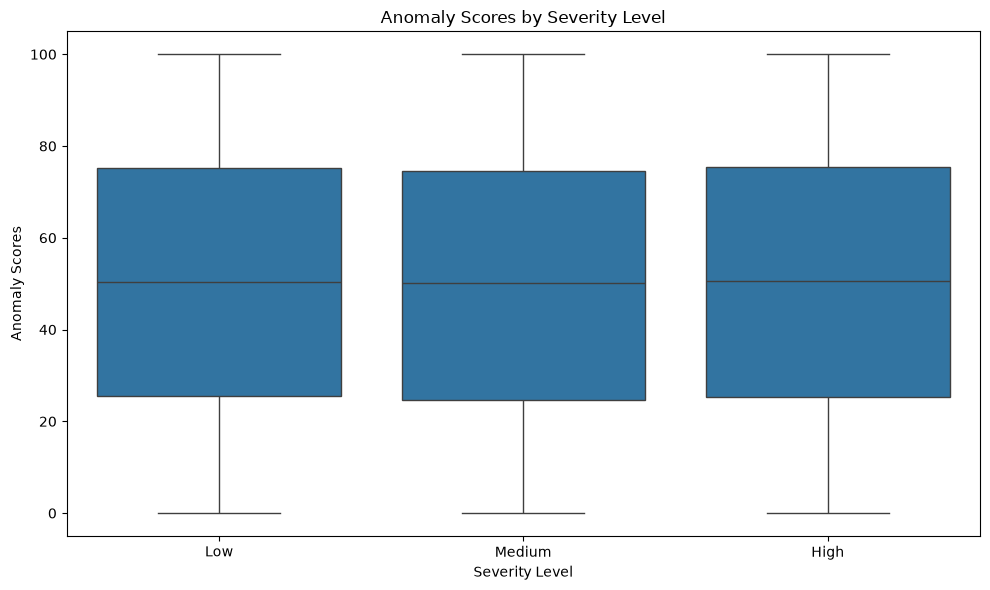

In [295]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=X,
    x="Severity Level",
    y="Anomaly Scores",
    order=["Low", "Medium", "High"]
)

plt.title("Anomaly Scores by Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Anomaly Scores")

plt.tight_layout()
plt.show()


Аналіз показав, що розподіл Anomaly Scores для рівнів критичності Low, Medium та High майже однаковий. Медіанні значення становлять приблизно 50, а міжквартильні діапазони практично збігаються. Отже, за отриманими даними не спостерігається вираженої залежності між оцінкою аномальності та рівнем критичності.

*Частина 4:* Підготовка даних до навчання: розділити дані на training та test вибірки; виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

4.1. Розділення даних на навчальну та тестову вибірки
Для навчання моделей використаємо 70% даних, а для тестування - 30%.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df[features],
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nРозмір цільової змінної:")
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Розмір навчальної вибірки: (28000, 10)
Розмір тестової вибірки: (12000, 10)

Розмір цільової змінної:
y_train: (28000,)
y_test: (12000,)


4.2. Перевірка розподілу класів у вибірках

In [297]:

print("Розподіл класів у навчальній вибірці:")
print(y_train.value_counts())

print("\nРозподіл класів у тестовій вибірці:")
print(y_test.value_counts())

print("\nВідсотковий розподіл класів (training):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nВідсотковий розподіл класів (test):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Розподіл класів у навчальній вибірці:
IDS/IPS Alerts
0    14035
1    13965
Name: count, dtype: int64

Розподіл класів у тестовій вибірці:
IDS/IPS Alerts
0    6015
1    5985
Name: count, dtype: int64

Відсотковий розподіл класів (training):
IDS/IPS Alerts
0    50.12
1    49.88
Name: proportion, dtype: float64

Відсотковий розподіл класів (test):
IDS/IPS Alerts
0    50.12
1    49.88
Name: proportion, dtype: float64


4.3. Заповнення пропущених значень та кодування категоріальних ознак

In [ ]:
# Створення копій вибірок
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

# Заповнення пропусків у числових ознаках
num_imputer = SimpleImputer(strategy="median")

X_train_processed[numerical_features] = num_imputer.fit_transform(
    X_train[numerical_features]
)

X_test_processed[numerical_features] = num_imputer.transform(
    X_test[numerical_features]
)

# Заповнення пропусків у категоріальних ознаках
X_train_processed[categorical_features] = (
    X_train_processed[categorical_features].fillna("Unknown")
)

X_test_processed[categorical_features] = (
    X_test_processed[categorical_features].fillna("Unknown")
)

# Кодування категоріальних ознак
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

train_cat = encoder.fit_transform(
    X_train_processed[categorical_features]
)

test_cat = encoder.transform(
    X_test_processed[categorical_features]
)

# Назви закодованих колонок
encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

# Формування навчальної вибірки
X_train_encoded = pd.concat([
    X_train_processed[numerical_features].reset_index(drop=True),
    pd.DataFrame(train_cat, columns=encoded_columns)
], axis=1)

# Формування тестової вибірки
X_test_encoded = pd.concat([
    X_test_processed[numerical_features].reset_index(drop=True),
    pd.DataFrame(test_cat, columns=encoded_columns)
], axis=1)

print("Розмір навчальної вибірки після кодування:")
print(X_train_encoded.shape)

print("\nРозмір тестової вибірки після кодування:")
print(X_test_encoded.shape)


Розмір навчальної вибірки після кодування:
(28000, 20)

Розмір тестової вибірки після кодування:
(12000, 20)


4.4. Масштабування числових ознак

In [ ]:
# Створення копій закодованих вибірок
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Ініціалізація StandardScaler
scaler = StandardScaler()

# Масштабування числових ознак
X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train_encoded[numerical_features]
)

X_test_scaled[numerical_features] = scaler.transform(
    X_test_encoded[numerical_features]
)

print("Масштабування виконано.")

print("\nПерші 5 записів навчальної вибірки:")
print(X_train_scaled.head())


Масштабування виконано.

Перші 5 записів навчальної вибірки:
   Source Port  Destination Port  Packet Length  Anomaly Scores  \
0     1.709603          0.327874      -0.541368        1.053803   
1    -0.991295          1.086656       1.541937        0.088435   
2     0.676647         -0.668614      -0.010330       -0.753747   
3     1.574412         -0.682416       0.105009       -0.492799   
4     1.556409         -0.491291      -1.250220        1.616645   

   Protocol_ICMP  Protocol_TCP  Protocol_UDP  Packet Type_Control  \
0            1.0           0.0           0.0                  0.0   
1            1.0           0.0           0.0                  0.0   
2            0.0           1.0           0.0                  0.0   
3            1.0           0.0           0.0                  0.0   
4            0.0           1.0           0.0                  0.0   

   Packet Type_Data  Traffic Type_DNS  Traffic Type_FTP  Traffic Type_HTTP  \
0               1.0               0.0      

4.5. Перевірка результатів масштабування

In [300]:

print("Середні значення після масштабування:")
print(
    X_train_scaled[numerical_features]
    .mean()
    .round(4)
)

print("\nСтандартні відхилення після масштабування:")
print(
    X_train_scaled[numerical_features]
    .std(ddof=0)
    .round(4)
)


Середні значення після масштабування:
Source Port        -0.0
Destination Port   -0.0
Packet Length      -0.0
Anomaly Scores     -0.0
dtype: float64

Стандартні відхилення після масштабування:
Source Port         1.0
Destination Port    1.0
Packet Length       1.0
Anomaly Scores      1.0
dtype: float64


4.6. Порівняння даних до та після масштабування

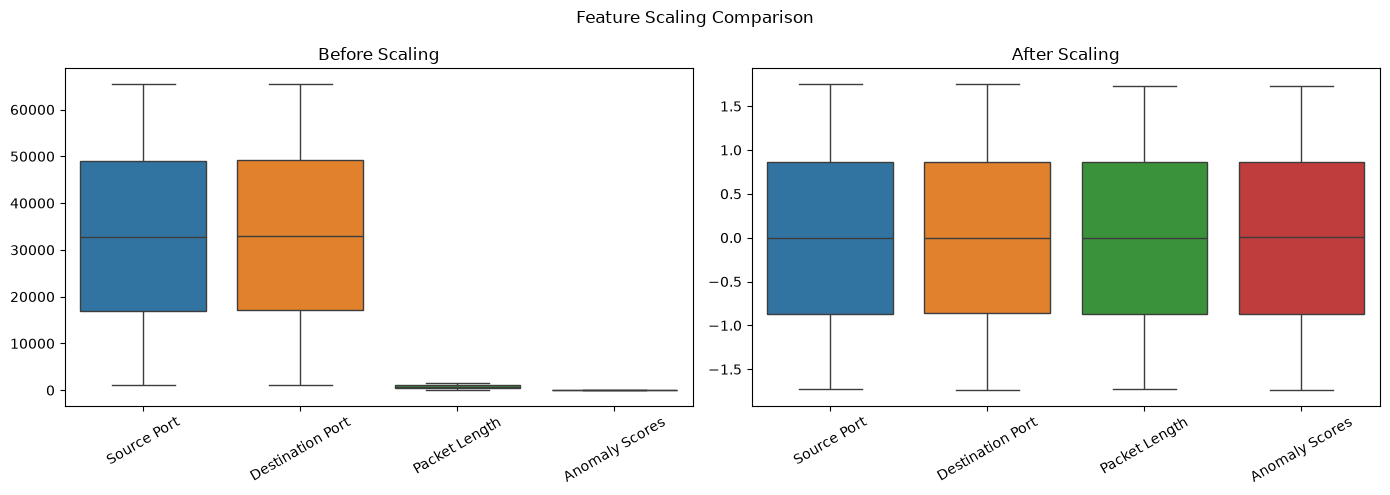

In [301]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# До масштабування
sns.boxplot(
    data=X_train_encoded[numerical_features],
    ax=axes[0]
)

axes[0].set_title("Before Scaling")
axes[0].tick_params(axis="x", rotation=30)

# Після масштабування
sns.boxplot(
    data=X_train_scaled[numerical_features],
    ax=axes[1]
)

axes[1].set_title("After Scaling")
axes[1].tick_params(axis="x", rotation=30)

plt.suptitle("Feature Scaling Comparison")
plt.tight_layout()
plt.show()


4.7. Підготовка остаточних вибірок для класифікаторів

In [302]:

# Дані для kNN та SVM
X_train_knn_svm = X_train_scaled
X_test_knn_svm = X_test_scaled

# Дані для Decision Tree, Random Forest та AdaBoost
X_train_tree = X_train_encoded
X_test_tree = X_test_encoded

print("Дані для kNN та SVM:")
print("Training:", X_train_knn_svm.shape)
print("Test:", X_test_knn_svm.shape)

print("\nДані для деревоподібних моделей:")
print("Training:", X_train_tree.shape)
print("Test:", X_test_tree.shape)

print("\nПеревірка пропущених значень:")
print("Training:", X_train_encoded.isnull().sum().sum())
print("Test:", X_test_encoded.isnull().sum().sum())


Дані для kNN та SVM:
Training: (28000, 20)
Test: (12000, 20)

Дані для деревоподібних моделей:
Training: (28000, 20)
Test: (12000, 20)

Перевірка пропущених значень:
Training: 0
Test: 0


**Частина 5:** Навчання моделей - навчити наступні класифікатори: 
* k-Nearest Neighbors (kNN)
* Decision Tree
* Support Vector Machine (SVM)
* Random Forest
* AdaBoost

5.1. Навчання класифікатора k-Nearest Neighbors (kNN)

In [304]:

# Створення моделі kNN
knn = KNeighborsClassifier(n_neighbors=5)

# Навчання моделі
knn.fit(X_train_knn_svm, y_train)

# Прогнозування на тестовій вибірці
y_pred_knn = knn.predict(X_test_knn_svm)

# Оцінка точності
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("kNN Classifier")
print("Accuracy:", round(accuracy_knn, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))


kNN Classifier
Accuracy: 0.5045

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.50      0.50      6015
           1       0.50      0.51      0.51      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.50     12000
weighted avg       0.50      0.50      0.50     12000


Confusion Matrix:
[[3019 2996]
 [2950 3035]]


5.2. Навчання класифікатора Decision Tree

In [305]:

# Створення моделі Decision Tree
dt = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)

# Навчання моделі
dt.fit(X_train_tree, y_train)

# Прогнозування
y_pred_dt = dt.predict(X_test_tree)

# Оцінка точності
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Classifier")
print("Accuracy:", round(accuracy_dt, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))


Decision Tree Classifier
Accuracy: 0.5117

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.52      0.51      6015
           1       0.51      0.51      0.51      5985

    accuracy                           0.51     12000
   macro avg       0.51      0.51      0.51     12000
weighted avg       0.51      0.51      0.51     12000


Confusion Matrix:
[[3106 2909]
 [2951 3034]]


5.2.1. Візуалізація дерева рішень

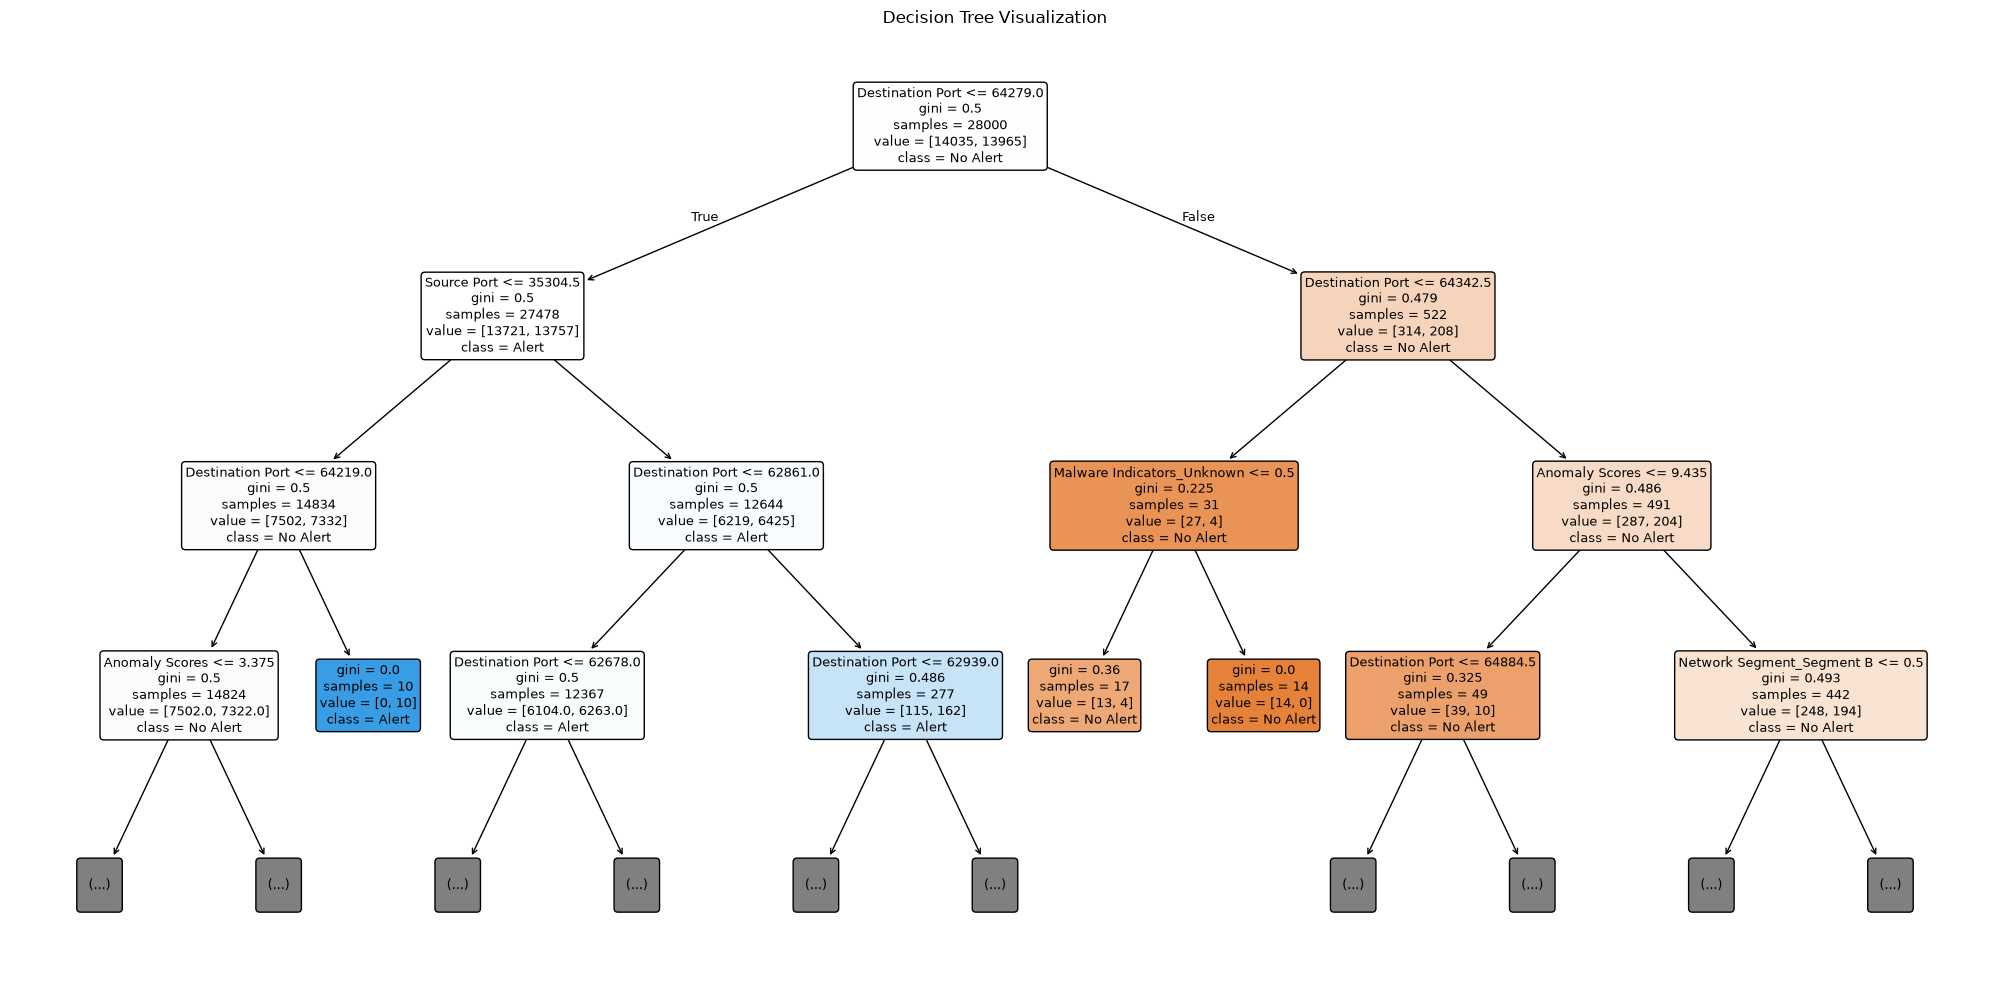

In [306]:

plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X_train_tree.columns,
    class_names=["No Alert", "Alert"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()


5.3. Навчання класифікатора Support Vector Machine (SVM)

In [307]:

# Створення моделі SVM
svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

# Навчання моделі
svm.fit(X_train_knn_svm, y_train)

# Прогнозування
y_pred_svm = svm.predict(X_test_knn_svm)

# Оцінка точності
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Classifier")
print("Accuracy:", round(accuracy_svm, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))


SVM Classifier
Accuracy: 0.4991

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.52      0.51      6015
           1       0.50      0.48      0.49      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.50     12000
weighted avg       0.50      0.50      0.50     12000


Confusion Matrix:
[[3141 2874]
 [3137 2848]]


5.4. Навчання класифікатора Random Forest

In [ ]:
# Створення моделі Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=20,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Навчання моделі
rf.fit(X_train_tree, y_train)

# Прогнозування
y_pred_rf = rf.predict(X_test_tree)

# Оцінка точності
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Classifier")
print("Accuracy:", round(accuracy_rf, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Classifier
Accuracy: 0.5014

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.52      0.51      6015
           1       0.50      0.48      0.49      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.50     12000
weighted avg       0.50      0.50      0.50     12000


Confusion Matrix:
[[3138 2877]
 [3106 2879]]


5.4.1. Візуалізація важливості ознак Random Forest

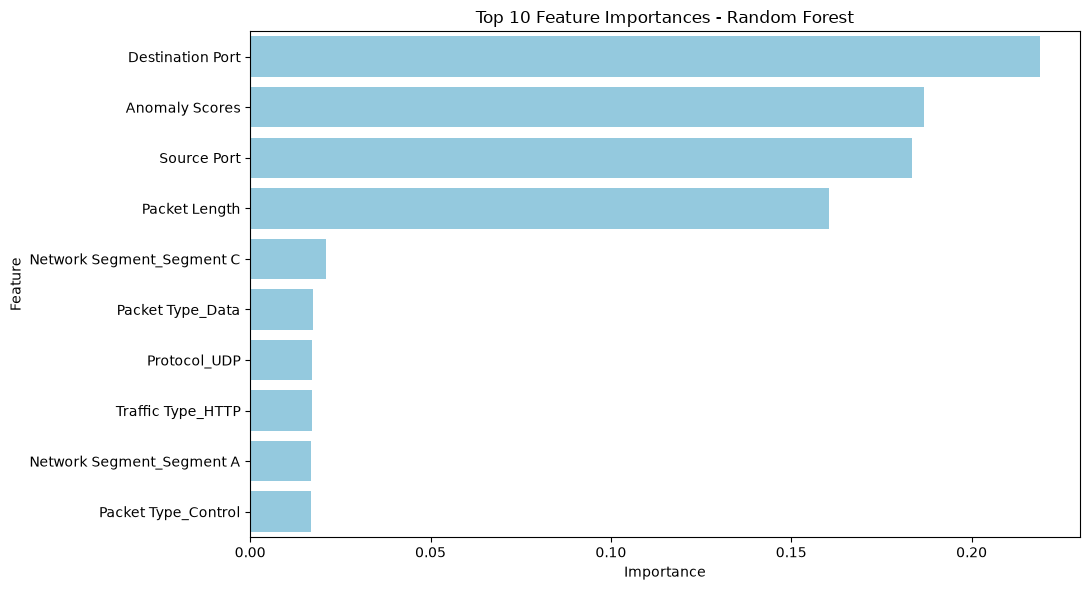

In [309]:

# Визначення важливості ознак
feature_importance = pd.DataFrame({
    "Feature": X_train_tree.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Вибір 10 найважливіших ознак
top_features = feature_importance.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="skyblue"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


5.5. Навчання класифікатора AdaBoost

In [310]:

# Створення моделі AdaBoost
ada = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

# Навчання моделі
ada.fit(X_train_tree, y_train)

# Прогнозування
y_pred_ada = ada.predict(X_test_tree)

# Оцінка точності
accuracy_ada = accuracy_score(y_test, y_pred_ada)

print("AdaBoost Classifier")
print("Accuracy:", round(accuracy_ada, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_ada))


AdaBoost Classifier
Accuracy: 0.498

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.38      0.43      6015
           1       0.50      0.61      0.55      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.49     12000
weighted avg       0.50      0.50      0.49     12000


Confusion Matrix:
[[2300 3715]
 [2309 3676]]


5.6. Перевірка навчання всіх класифікаторів

In [311]:

trained_models = {
    "kNN": knn,
    "Decision Tree": dt,
    "SVM": svm,
    "Random Forest": rf,
    "AdaBoost": ada
}

print("Навчені класифікатори:")

for name, model in trained_models.items():
    print(f"{name}: {type(model).__name__}")

print("\nЗагальна кількість моделей:", len(trained_models))


Навчені класифікатори:
kNN: KNeighborsClassifier
Decision Tree: DecisionTreeClassifier
SVM: SVC
Random Forest: RandomForestClassifier
AdaBoost: AdaBoostClassifier

Загальна кількість моделей: 5


5.7. Попереднє порівняння точності моделей

Попереднє порівняння моделей:
        Model  Accuracy
Decision Tree    0.5117
          kNN    0.5045
Random Forest    0.5014
          SVM    0.4991
     AdaBoost    0.4980


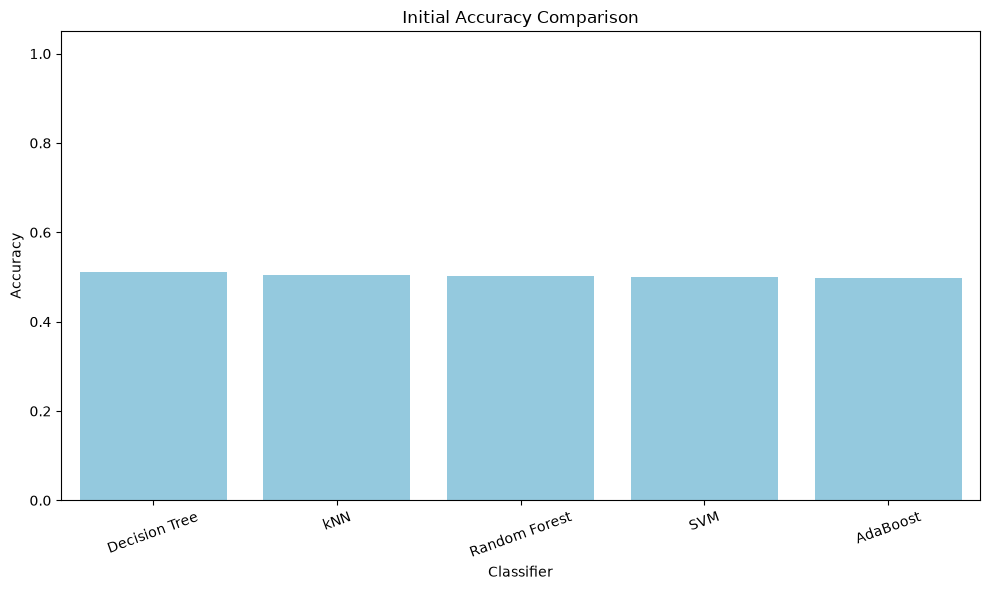

In [312]:

accuracy_results = pd.DataFrame({
    "Model": [
        "kNN",
        "Decision Tree",
        "SVM",
        "Random Forest",
        "AdaBoost"
    ],
    "Accuracy": [
        accuracy_knn,
        accuracy_dt,
        accuracy_svm,
        accuracy_rf,
        accuracy_ada
    ]
})

accuracy_results = accuracy_results.sort_values(
    by="Accuracy",
    ascending=False
)

print("Попереднє порівняння моделей:")
print(accuracy_results.round(4).to_string(index=False))

# Побудова графіка
plt.figure(figsize=(10, 6))

sns.barplot(
    data=accuracy_results,
    x="Model",
    y="Accuracy",
    color="skyblue"
)

plt.title("Initial Accuracy Comparison")
plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


**Частина 6:** Підбір гіперпараметрів: для kNN підібрати оптимальне значення n_neighbors, для SVM за допомогою GridSearchCV підібрати оптимальні значення C та gamma. За бажанням можна дослідити вплив гіперпараметрів і для інших моделей.

6.1. Налаштування кросвалідації
Для оцінювання різних комбінацій гіперпараметрів використано п'ятикратну стратифіковану кросвалідацію (StratifiedKFold).

In [314]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Кількість блоків кросвалідації:", cv.n_splits)
print("Метод: Stratified K-Fold")


Кількість блоків кросвалідації: 5
Метод: Stratified K-Fold


6.2. Підбір оптимального значення n_neighbors для kNN

In [ ]:
# Попередня обробка
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Конвеєр kNN
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

# Підбір параметрів із обмеженням складності моделі
grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={
        "classifier__n_neighbors": list(range(7, 52, 4)),
        "classifier__weights": ["uniform"]
    },
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

# Навчання
grid_knn.fit(X_train, y_train)

# Найкраща модель
best_knn = grid_knn.best_estimator_

print("Найкращі параметри:", grid_knn.best_params_)
print("Найкращий CV F1-macro:", round(grid_knn.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Найкращі параметри: {'classifier__n_neighbors': 51, 'classifier__weights': 'uniform'}
Найкращий CV F1-macro: 0.4986


6.3. Візуалізація залежності якості kNN від кількості сусідів

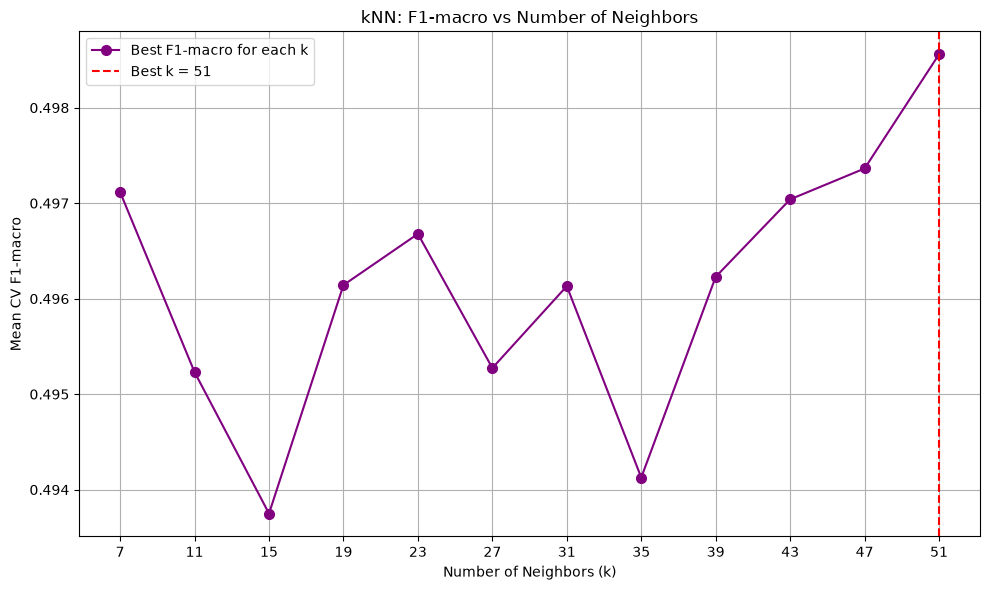

In [316]:

# Результати GridSearchCV
knn_results = pd.DataFrame(grid_knn.cv_results_)

# Вибір найкращого F1-macro для кожного значення k
knn_plot = (
    knn_results.groupby("param_classifier__n_neighbors")[
        "mean_test_score"
    ]
    .max()
    .reset_index()
)

# Перетворення значень k у цілі числа
knn_plot["param_classifier__n_neighbors"] = (
    knn_plot["param_classifier__n_neighbors"].astype(int)
)

# Сортування за кількістю сусідів
knn_plot = knn_plot.sort_values(
    "param_classifier__n_neighbors"
)

# Найкраще значення k
best_k = grid_knn.best_params_["classifier__n_neighbors"]

# Побудова графіка
plt.figure(figsize=(10, 6))

plt.plot(
    knn_plot["param_classifier__n_neighbors"],
    knn_plot["mean_test_score"],
    marker="o",
    markersize=7,
    color="purple",
    label="Best F1-macro for each k"
)

plt.axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=f"Best k = {best_k}"
)

plt.title("kNN: F1-macro vs Number of Neighbors")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean CV F1-macro")
plt.xticks(range(7, 52, 4))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


6.4. Навчання kNN з оптимальним значенням n_neighbors

In [317]:

# Найкраща модель kNN
best_knn = grid_knn.best_estimator_

print("Оптимальне значення n_neighbors:")
print(best_knn.named_steps["classifier"].n_neighbors)

print("\nОптимальний метод зважування сусідів:")
print(best_knn.named_steps["classifier"].weights)

print("\nНайкраща модель:")
print(best_knn)

# Модель уже навчена GridSearchCV
# Прогнозування на тестовій вибірці
y_pred_knn_opt = best_knn.predict(X_test)

print("\nКількість прогнозованих об'єктів:")
print(len(y_pred_knn_opt))


Оптимальне значення n_neighbors:
51

Оптимальний метод зважування сусідів:
uniform

Найкраща модель:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Source Port',
                                                   'Destination Port',
                                                   'Packet Length',
                                                   'Anomaly Scores']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                     

6.5. Підбір оптимальних параметрів C та gamma для SVM

In [318]:

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", cache_size=1000))
])

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid={
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    },
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=2
)

grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_

print("Найкращі параметри:", grid_svm.best_params_)
print("Найкращий CV F1-macro:", grid_svm.best_score_)


Fitting 3 folds for each of 9 candidates, totalling 27 fits
Найкращі параметри: {'classifier__C': 0.1, 'classifier__gamma': 0.01}
Найкращий CV F1-macro: 0.5022764221524623


6.6. Виведення результатів підбору параметрів SVM

In [319]:

# Результати підбору параметрів SVM
svm_results = pd.DataFrame(grid_svm.cv_results_)

svm_table = svm_results[
    [
        "param_classifier__C",
        "param_classifier__gamma",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].copy()

svm_table = svm_table.sort_values(
    by="rank_test_score"
)

print("Результати GridSearchCV для SVM:")
print(svm_table.to_string(index=False))


Результати GridSearchCV для SVM:
 param_classifier__C param_classifier__gamma  mean_test_score  std_test_score  rank_test_score
                 0.1                    0.01         0.502276        0.001640                1
                 0.1                     0.1         0.501711        0.005732                2
                 1.0                    0.01         0.501310        0.002716                3
                 0.1                   scale         0.500829        0.004387                4
                10.0                   scale         0.500686        0.005850                5
                 1.0                   scale         0.500472        0.004445                6
                 1.0                     0.1         0.500128        0.005054                7
                10.0                     0.1         0.499695        0.003940                8
                10.0                    0.01         0.497739        0.002438                9


6.7. Побудова Heatmap результатів GridSearchCV для SVM

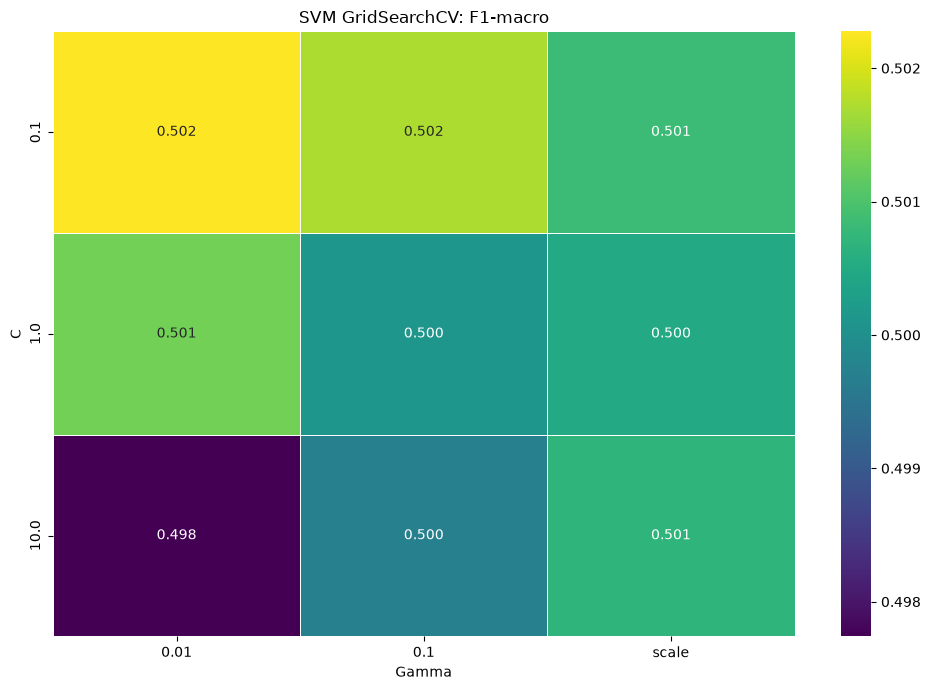

In [320]:

# Формування таблиці для heatmap
svm_pivot = svm_results.pivot(
    index="param_classifier__C",
    columns="param_classifier__gamma",
    values="mean_test_score"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    svm_pivot,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    linewidths=0.5
)

plt.title("SVM GridSearchCV: F1-macro")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.tight_layout()
plt.show()


6.8. Навчання SVM з оптимальними параметрами

In [321]:

# Найкраща модель SVM
best_svm = grid_svm.best_estimator_

print("Оптимальні параметри SVM:")
print("C:", best_svm.named_steps["classifier"].C)
print("Gamma:", best_svm.named_steps["classifier"].gamma)

print("\nНайкраща модель:")
print(best_svm)

# Модель уже навчена GridSearchCV
y_pred_svm_opt = best_svm.predict(X_test)

print("\nКількість прогнозованих об'єктів:")
print(len(y_pred_svm_opt))


Оптимальні параметри SVM:
C: 0.1
Gamma: 0.01

Найкраща модель:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Source Port',
                                                   'Destination Port',
                                                   'Packet Length',
                                                   'Anomaly Scores']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value

6.9. Порівняння результатів підбору гіперпараметрів

In [322]:

tuning_results = pd.DataFrame({
    "Model": ["kNN", "SVM"],
    "Best Parameters": [
        str(grid_knn.best_params_),
        str(grid_svm.best_params_)
    ],
    "Best CV F1-macro": [
        grid_knn.best_score_,
        grid_svm.best_score_
    ]
})

print("Порівняння оптимізованих моделей:")
print(tuning_results.round(4).to_string(index=False))


Порівняння оптимізованих моделей:
Model                                                   Best Parameters  Best CV F1-macro
  kNN {'classifier__n_neighbors': 51, 'classifier__weights': 'uniform'}            0.4986
  SVM                 {'classifier__C': 0.1, 'classifier__gamma': 0.01}            0.5023


6.9.1. Графічне порівняння результатів

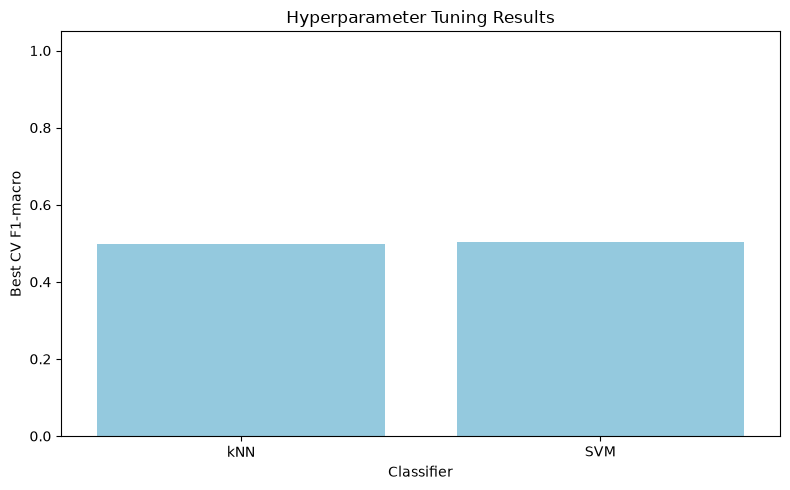

In [323]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=tuning_results,
    x="Model",
    y="Best CV F1-macro",
    color="skyblue"
)

plt.title("Hyperparameter Tuning Results")
plt.xlabel("Classifier")
plt.ylabel("Best CV F1-macro")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


**Частина 7:** Порівняння та оцінювання моделей
Порівняти результати всіх навчених класифікаторів та визначити найкращу модель для обраного датасета.
Для моделей вивести та проаналізувати:
sklearn.metrics.classification_report
sklearn.metrics.confusion_matrix

7.1. Оцінювання класифікатора k-Nearest Neighbors (kNN)

In [325]:

# Прогнозування оптимізованої моделі kNN
y_pred_knn = best_knn.predict(X_test)

print("kNN Classification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No Alert", "Alert"],
    zero_division=0
))

print("\nkNN Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn, labels=[0, 1]))


kNN Classification Report:
              precision    recall  f1-score   support

    No Alert       0.51      0.51      0.51      6015
       Alert       0.50      0.50      0.50      5985

    accuracy                           0.51     12000
   macro avg       0.51      0.51      0.51     12000
weighted avg       0.51      0.51      0.51     12000


kNN Confusion Matrix:
[[3082 2933]
 [3002 2983]]


7.2. Оцінювання класифікатора Decision Tree

In [326]:

# Прогнозування Decision Tree
y_pred_dt = dt.predict(X_test_tree)

print("Decision Tree Classification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["No Alert", "Alert"],
    zero_division=0
))

print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt, labels=[0, 1]))


Decision Tree Classification Report:
              precision    recall  f1-score   support

    No Alert       0.51      0.52      0.51      6015
       Alert       0.51      0.51      0.51      5985

    accuracy                           0.51     12000
   macro avg       0.51      0.51      0.51     12000
weighted avg       0.51      0.51      0.51     12000


Decision Tree Confusion Matrix:
[[3106 2909]
 [2951 3034]]


7.3. Оцінювання класифікатора Support Vector Machine (SVM)

In [327]:

# Прогнозування оптимізованої моделі SVM
y_pred_svm = best_svm.predict(X_test)

print("SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["No Alert", "Alert"],
    zero_division=0
))

print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm, labels=[0, 1]))


SVM Classification Report:
              precision    recall  f1-score   support

    No Alert       0.50      0.54      0.52      6015
       Alert       0.49      0.45      0.47      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.50     12000
weighted avg       0.50      0.50      0.50     12000


SVM Confusion Matrix:
[[3255 2760]
 [3281 2704]]


7.4. Оцінювання класифікатора Random Forest

In [328]:

# Прогнозування Random Forest
y_pred_rf = rf.predict(X_test_tree)

print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Alert", "Alert"],
    zero_division=0
))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf, labels=[0, 1]))


Random Forest Classification Report:
              precision    recall  f1-score   support

    No Alert       0.50      0.52      0.51      6015
       Alert       0.50      0.48      0.49      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.50     12000
weighted avg       0.50      0.50      0.50     12000


Random Forest Confusion Matrix:
[[3138 2877]
 [3106 2879]]


7.5. Оцінювання класифікатора AdaBoost

In [329]:

# Прогнозування AdaBoost
y_pred_ada = ada.predict(X_test_tree)

print("AdaBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_ada,
    target_names=["No Alert", "Alert"],
    zero_division=0
))

print("\nAdaBoost Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ada, labels=[0, 1]))


AdaBoost Classification Report:
              precision    recall  f1-score   support

    No Alert       0.50      0.38      0.43      6015
       Alert       0.50      0.61      0.55      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.49     12000
weighted avg       0.50      0.50      0.49     12000


AdaBoost Confusion Matrix:
[[2300 3715]
 [2309 3676]]


7.6. Побудова матриць помилок для всіх класифікаторів

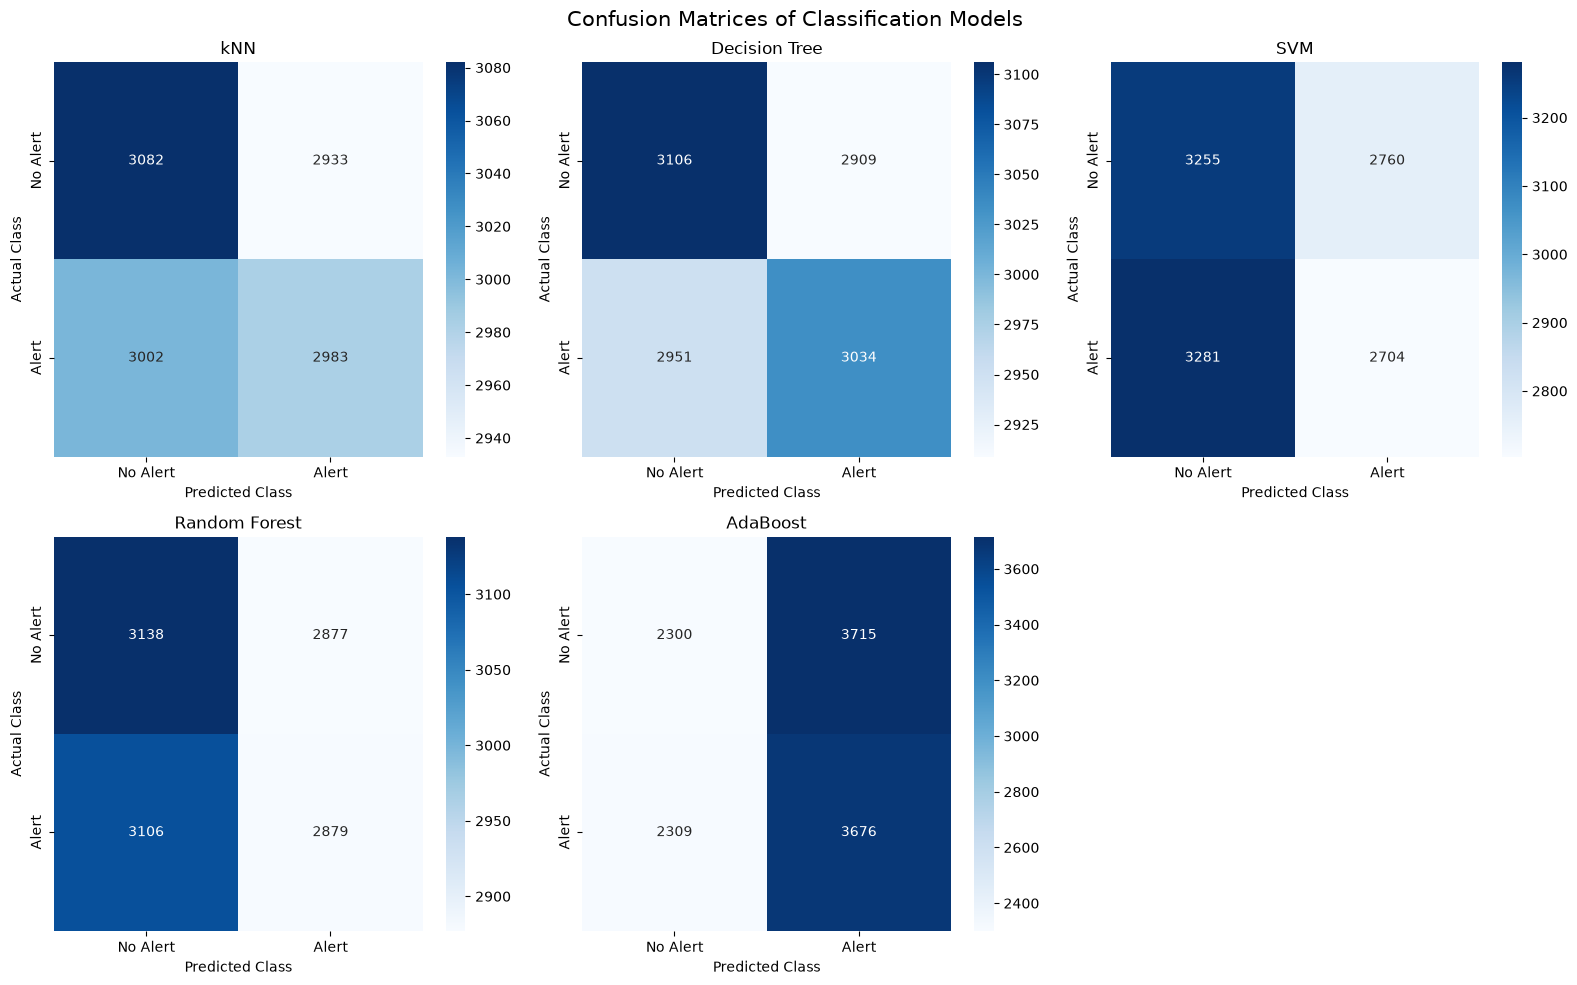

In [330]:

# Прогнози всіх моделей
predictions = {
    "kNN": y_pred_knn,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["No Alert", "Alert"],
        yticklabels=["No Alert", "Alert"]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

# Видалення зайвого графіка
for j in range(len(predictions), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Confusion Matrices of Classification Models",
    fontsize=15
)

plt.tight_layout()
plt.show()


7.7. Обчислення основних метрик для всіх моделей

In [331]:

results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

results_df = pd.DataFrame(results)

print("Результати оцінювання моделей:")
print(results_df.round(4).to_string(index=False))


Результати оцінювання моделей:
        Model  Accuracy  Precision  Recall  F1-score
          kNN    0.5054     0.5054  0.5054    0.5054
Decision Tree    0.5117     0.5117  0.5117    0.5116
          SVM    0.4966     0.4964  0.4965    0.4955
Random Forest    0.5014     0.5014  0.5014    0.5012
     AdaBoost    0.4980     0.4982  0.4983    0.4913


7.8. Формування загальної таблиці порівняння класифікаторів

In [332]:

# Сортування моделей за F1-score
results_sorted = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("Порівняння класифікаторів:")
print(results_sorted.round(4).to_string(index=False))


Порівняння класифікаторів:
        Model  Accuracy  Precision  Recall  F1-score
Decision Tree    0.5117     0.5117  0.5117    0.5116
          kNN    0.5054     0.5054  0.5054    0.5054
Random Forest    0.5014     0.5014  0.5014    0.5012
          SVM    0.4966     0.4964  0.4965    0.4955
     AdaBoost    0.4980     0.4982  0.4983    0.4913


7.9. Графічне порівняння результатів класифікації

<Figure size 1300x700 with 0 Axes>

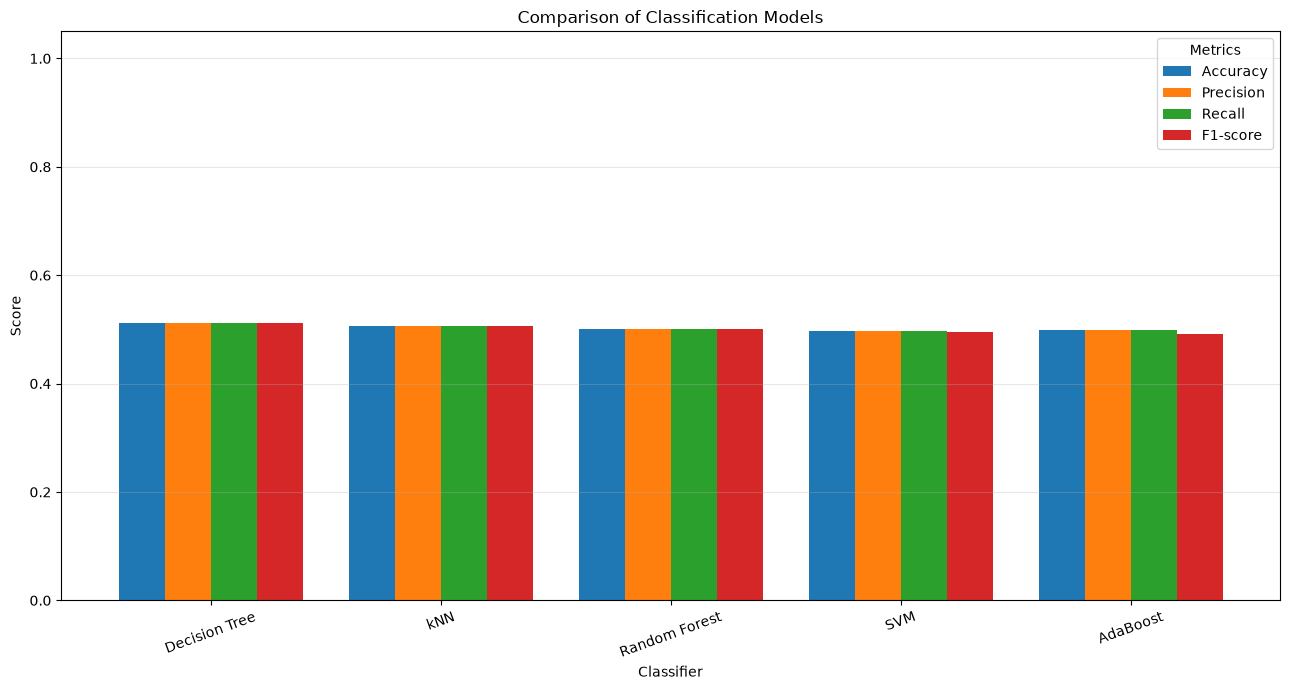

In [333]:

# Підготовка даних для графіка
results_plot = results_sorted.set_index("Model")

plt.figure(figsize=(13, 7))

results_plot[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Comparison of Classification Models")
plt.xlabel("Classifier")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


7.10. Визначення найкращої моделі

In [334]:

# Визначення найкращої моделі
best_model_name = results_sorted.iloc[0]["Model"]
best_accuracy = results_sorted.iloc[0]["Accuracy"]
best_precision = results_sorted.iloc[0]["Precision"]
best_recall = results_sorted.iloc[0]["Recall"]
best_f1 = results_sorted.iloc[0]["F1-score"]

print("Найкраща модель:", best_model_name)

print("\nМетрики найкращої моделі:")
print("Accuracy:", round(best_accuracy, 4))
print("Precision:", round(best_precision, 4))
print("Recall:", round(best_recall, 4))
print("F1-score:", round(best_f1, 4))


Найкраща модель: Decision Tree

Метрики найкращої моделі:
Accuracy: 0.5117
Precision: 0.5117
Recall: 0.5117
F1-score: 0.5116


7.10.1. Детальний аналіз найкращої моделі

Найкращий класифікатор: Decision Tree

Classification Report:
              precision    recall  f1-score   support

    No Alert       0.51      0.52      0.51      6015
       Alert       0.51      0.51      0.51      5985

    accuracy                           0.51     12000
   macro avg       0.51      0.51      0.51     12000
weighted avg       0.51      0.51      0.51     12000


Confusion Matrix:
[[3106 2909]
 [2951 3034]]


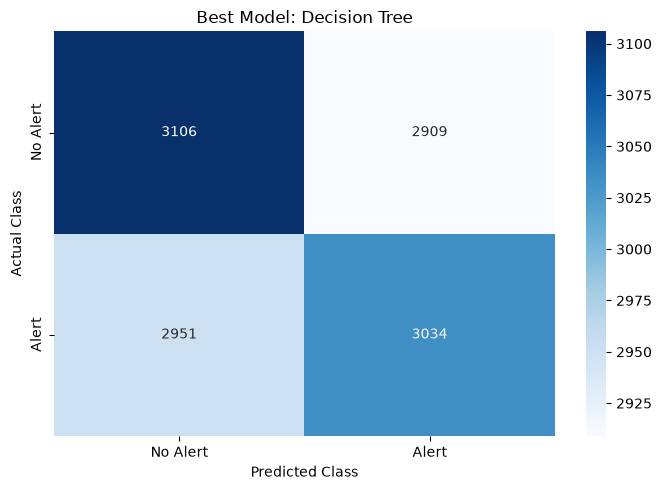

In [335]:

# Прогнози найкращої моделі
best_predictions = predictions[best_model_name]

print("Найкращий класифікатор:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Alert", "Alert"],
    zero_division=0
))

print("\nConfusion Matrix:")
best_cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

print(best_cm)

# Візуалізація
plt.figure(figsize=(7, 5))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Alert", "Alert"],
    yticklabels=["No Alert", "Alert"]
)

plt.title(f"Best Model: {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


7.10.2. Аналіз перенавчання моделей

Аналіз перенавчання моделей:
        Model  Train F1-macro  Test F1-macro    Gap
          kNN          0.5521         0.5054 0.0467
Decision Tree          0.5250         0.5116 0.0133
          SVM          0.5068         0.4955 0.0113
Random Forest          0.5912         0.5012 0.0900
     AdaBoost          0.5041         0.4913 0.0128


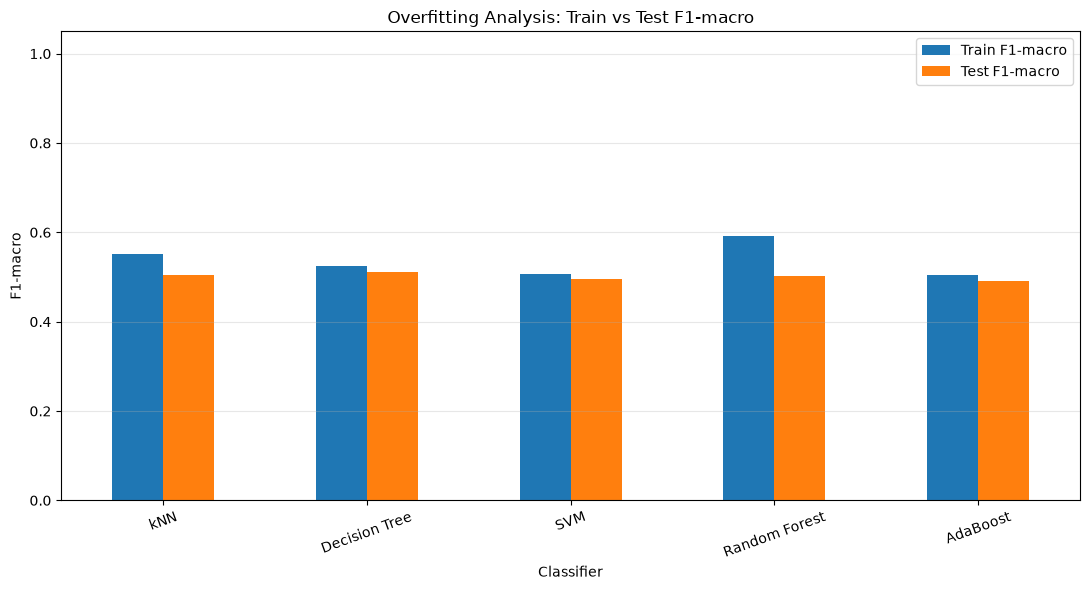

In [ ]:
models_to_check = {
    "kNN": (best_knn, X_train, X_test),
    "Decision Tree": (dt, X_train_tree, X_test_tree),
    "SVM": (best_svm, X_train, X_test),
    "Random Forest": (rf, X_train_tree, X_test_tree),
    "AdaBoost": (ada, X_train_tree, X_test_tree)
}

overfitting_results = []

for name, (model, train_data, test_data) in models_to_check.items():
    train_pred = model.predict(train_data)
    test_pred = model.predict(test_data)

    train_f1 = f1_score(
        y_train, train_pred, average="macro", zero_division=0
    )

    test_f1 = f1_score(
        y_test, test_pred, average="macro", zero_division=0
    )

    overfitting_results.append({
        "Model": name,
        "Train F1-macro": train_f1,
        "Test F1-macro": test_f1,
        "Gap": train_f1 - test_f1
    })

overfitting_df = pd.DataFrame(overfitting_results)

print("Аналіз перенавчання моделей:")
print(overfitting_df.round(4).to_string(index=False))

# Графічне порівняння
overfitting_df.set_index("Model")[
    ["Train F1-macro", "Test F1-macro"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Overfitting Analysis: Train vs Test F1-macro")
plt.xlabel("Classifier")
plt.ylabel("F1-macro")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


7.11. Автоматичне формування підсумкового висновку

In [337]:

print("ПІДСУМКОВИЙ ВИСНОВОК\n")

print(
    f"У ході порівняння п'яти класифікаторів "
    f"найкращий результат за метрикою F1-macro "
    f"показала модель {best_model_name}."
)

print(
    f"Модель досягла Accuracy = {best_accuracy:.4f}, "
    f"Precision = {best_precision:.4f}, "
    f"Recall = {best_recall:.4f} "
    f"та F1-score = {best_f1:.4f}."
)

print(
    "Отримані результати свідчать, що ця модель "
    "забезпечила найкращий баланс точності та повноти "
    "класифікації серед досліджених алгоритмів "
    "за обраною метрикою."
)


ПІДСУМКОВИЙ ВИСНОВОК

У ході порівняння п'яти класифікаторів найкращий результат за метрикою F1-macro показала модель Decision Tree.
Модель досягла Accuracy = 0.5117, Precision = 0.5117, Recall = 0.5117 та F1-score = 0.5116.
Отримані результати свідчать, що ця модель забезпечила найкращий баланс точності та повноти класифікації серед досліджених алгоритмів за обраною метрикою.


7.12. **Короткий висновок:**
У ході лабораторної роботи було проведено дослідження п'яти алгоритмів класифікації: k-Nearest Neighbors, Decision Tree, Support Vector Machine, Random Forest та AdaBoost. Для підготовки даних виконано обробку пропущених значень, кодування категоріальних ознак і масштабування числових характеристик. За допомогою GridSearchCV здійснено підбір оптимальних гіперпараметрів для моделей kNN та SVM.
За результатами порівняння найкращу якість класифікації продемонструвала модель Decision Tree, для якої значення F1-macro на тестовій вибірці становило 0,5116. Додатковий аналіз перенавчання показав, що оптимізація гіперпараметрів дозволила суттєво зменшити різницю між навчальними та тестовими показниками моделей kNN і Random Forest.
Водночас усі досліджені алгоритми продемонстрували відносно низьку якість класифікації, що може пояснюватися недостатньою інформативністю вибраних ознак та особливостями формування цільової змінної. Отримані результати підтверджують важливість правильного вибору ознак, попередньої обробки даних, налаштування гіперпараметрів та перевірки узагальнювальної здатності моделей.